In [58]:
# Day 5

# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# PyTorch
import torch
import torch.nn as nn

# Sklearn
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Other Libraries
import joblib
import os
import random

# Setting Random Seeds
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Device Configuration
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Libraries Imported Successfully!")

Device: cpu
Libraries Imported Successfully!


In [59]:
from google.colab import drive
drive.mount("/content/drive")

# Project Paths
dataset_path = "/content/drive/MyDrive/food_dataset"

project_path = "/content/drive/MyDrive/SmartFood_Rescue"

model_path = project_path + "/models"

evaluation_path = project_path + "/evaluation"

# Create Evaluation Folder
os.makedirs(evaluation_path, exist_ok=True)

# Load Dataset
train = pd.read_csv(
    dataset_path + "/train_prepared.csv"
)

# Load Preprocessor
preprocessor = joblib.load(
    model_path + "/preprocessor.pkl"
)

# Load Demand Thresholds
thresholds = joblib.load(
    model_path + "/demand_thresholds.pkl"
)

low_threshold = thresholds["low_threshold"]
high_threshold = thresholds["high_threshold"]

# Model Path
classification_model_path = (
    model_path + "/ann_classifier.pth"
)

print("Google Drive Mounted Successfully!")

print("\nTraining Dataset:", train.shape)

print("Preprocessor Loaded:", preprocessor is not None)

print("Low Threshold:", low_threshold)
print("High Threshold:", high_threshold)

print(
    "Classification Model Exists:",
    os.path.exists(classification_model_path)
)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive Mounted Successfully!

Training Dataset: (456548, 18)
Preprocessor Loaded: True
Low Threshold: 80.0
High Threshold: 243.0
Classification Model Exists: True


In [60]:
# Sorted Unique Weeks
weeks = sorted(train["week"].unique())

# 80:20 Chronological Split
split_index = int(len(weeks) * 0.8)

split_week = weeks[split_index]

# Training and Validation Data
train_data = train[train["week"] < split_week]

val_data = train[train["week"] >= split_week]

print("Split Week:", split_week)

print("Training Shape:", train_data.shape)
print("Validation Shape:", val_data.shape)

print(
    "Validation Weeks:",
    val_data["week"].min(),
    "-",
    val_data["week"].max()
)

# Creating Demand Categories
def classify_demand(orders):

    if orders <= low_threshold:
        return 0

    elif orders <= high_threshold:
        return 1

    else:
        return 2

# Actual Validation Labels
y_val = val_data["num_orders"].apply(
    classify_demand
).values

# Class Mapping
class_names = ["Low", "Medium", "High"]

print("\nActual Demand Distribution:")

print(
    pd.Series(y_val)
    .value_counts()
    .sort_index()
    .rename(index=dict(enumerate(class_names)))
)


Split Week: 117
Training Shape: (361348, 18)
Validation Shape: (95200, 18)
Validation Weeks: 117 - 145

Actual Demand Distribution:
Low       33167
Medium    32220
High      29813
Name: count, dtype: int64


In [61]:
# Separating Validation Features

X_val = val_data.drop(
    columns=["id", "num_orders"]
)

# Applying Existing Preprocessor
X_val_processed = preprocessor.transform(X_val)

# Convert Sparse Matrix to Dense Array
if hasattr(X_val_processed, "toarray"):
    X_val_processed = X_val_processed.toarray()

# Convert to Float32
X_val_processed = X_val_processed.astype(np.float32)

# Convert to PyTorch Tensor
X_val_tensor = torch.tensor(
    X_val_processed,
    dtype=torch.float32
).to(device)

# Convert Actual Labels to Tensor
y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long
).to(device)

print("Validation Preprocessing Completed!")

print("X_val:", X_val_tensor.shape)
print("y_val:", y_val_tensor.shape)


Validation Preprocessing Completed!
X_val: torch.Size([95200, 217])
y_val: torch.Size([95200])


In [62]:
# ANN Classification Architecture

class ANNClassifier(nn.Module):
  def __init__(self):
    super(ANNClassifier, self).__init__()

    self.model = nn.Sequential(
            nn.Linear(X_val_tensor.shape[1], 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 3)
        )

  def forward(self, x):
        return self.model(x)

# Initializing Model
ann_classifier = ANNClassifier().to(device)

# Loading Saved Weights
ann_classifier.load_state_dict(
    torch.load(
        classification_model_path,
        map_location=device,
        weights_only=True
    )
)

# Evaluation Mode
ann_classifier.eval()

print("ANN Classifier Loaded Successfully!")

print(ann_classifier)


ANN Classifier Loaded Successfully!
ANNClassifier(
  (model): Sequential(
    (0): Linear(in_features=217, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)


In [63]:
# Generating Predictions

with torch.no_grad():
    classification_outputs = ann_classifier(X_val_tensor)
    classification_predictions = torch.argmax(classification_outputs, dim=1)

# Converting to NumPy
y_pred = classification_predictions.cpu().numpy()
y_actual = y_val_tensor.cpu().numpy()

print("Validation Predictions Completed!")

print("Actual Records:", len(y_actual))
print("Predicted Records:", len(y_pred))

print("\nPrediction Distribution:")

print(pd.Series(y_pred).value_counts().sort_index().rename(index=dict(enumerate(class_names))))


Validation Predictions Completed!
Actual Records: 95200
Predicted Records: 95200

Prediction Distribution:
Low       30549
Medium    36564
High      28087
Name: count, dtype: int64


In [64]:
# Classification Evaluation Metrics

accuracy = accuracy_score(y_actual, y_pred)

precision = precision_score(
    y_actual,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_actual,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_actual,
    y_pred,
    average="macro",
    zero_division=0
)

print("ANN Classification Evaluation: ")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


ANN Classification Evaluation: 
Accuracy: 0.7672689075630252
Precision: 0.7778055705404059
Recall: 0.7679727320299868
F1 Score: 0.7712801300069204


In [65]:
# Detailed Classification Report

print("Classification Report:\n")
report = classification_report(
    y_actual,
    y_pred,
    labels=[0, 1, 2],
    target_names=["Low", "Medium", "High"],
    zero_division=0
)

print(report)


Classification Report:

              precision    recall  f1-score   support

         Low       0.84      0.78      0.81     33167
      Medium       0.64      0.73      0.68     32220
        High       0.85      0.80      0.82     29813

    accuracy                           0.77     95200
   macro avg       0.78      0.77      0.77     95200
weighted avg       0.78      0.77      0.77     95200



In [66]:
# Confusion Matrix Calculations

cm = confusion_matrix(
    y_actual,
    y_pred,
    labels=[0, 1, 2]
)

cm_normalized = confusion_matrix(
    y_actual,
    y_pred,
    labels=[0, 1, 2],
    normalize="true"
)

In [67]:
# Save Evaluation Metrics

metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1_Score": f1
}

metrics_df = pd.DataFrame([metrics])

metrics_df.to_csv(
    evaluation_path + "/classification_metrics.csv",
    index=False
)

print("Classification Metrics Saved Successfully!")

Classification Metrics Saved Successfully!


In [68]:
# Generate Detailed Classification Report

report = classification_report(
    y_actual,
    y_pred,
    labels=[0, 1, 2],
    target_names=["Low", "Medium", "High"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    evaluation_path + "/classification_report.csv"
)

print("Classification Report Saved Successfully!")

Classification Report Saved Successfully!


In [69]:
# Save Original Confusion Matrix

cm_df = pd.DataFrame(
    cm,
    index=["Actual_Low", "Actual_Medium", "Actual_High"],
    columns=["Predicted_Low", "Predicted_Medium", "Predicted_High"]
)

cm_df.to_csv(
    evaluation_path + "/confusion_matrix.csv"
)


# Save Normalized Confusion Matrix

cm_normalized_df = pd.DataFrame(
    cm_normalized,
    index=["Actual_Low", "Actual_Medium", "Actual_High"],
    columns=["Predicted_Low", "Predicted_Medium", "Predicted_High"]
)

cm_normalized_df.to_csv(
    evaluation_path + "/normalized_confusion_matrix.csv"
)

print("Both Confusion Matrices Saved Successfully!")

Both Confusion Matrices Saved Successfully!


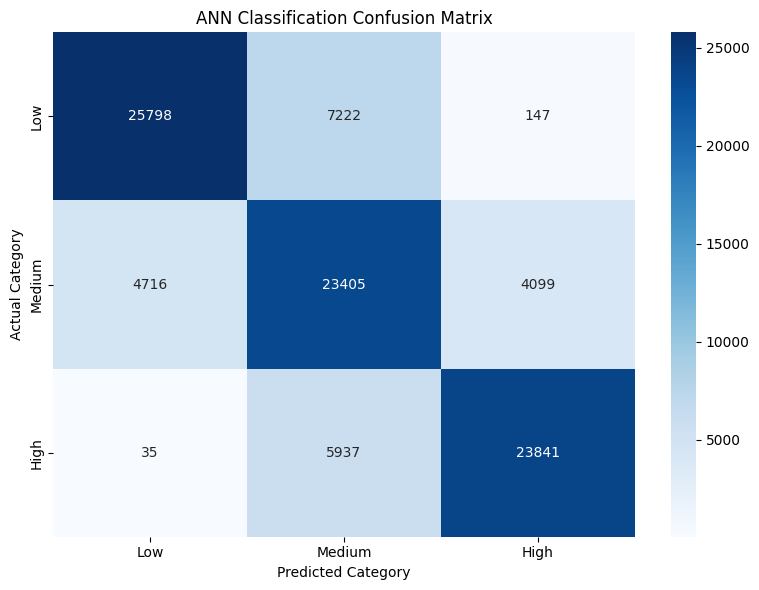

In [70]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("ANN Classification Confusion Matrix")

plt.tight_layout()

plt.savefig(
    evaluation_path + "/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

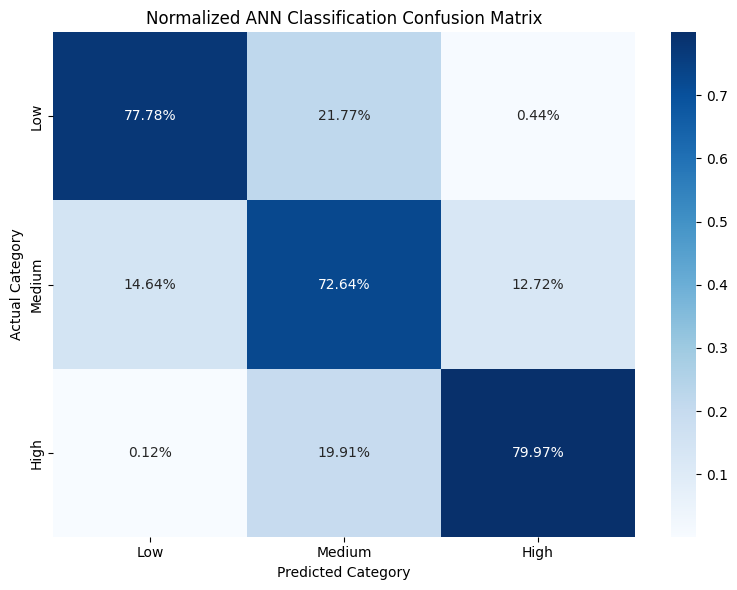

In [71]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2%",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Normalized ANN Classification Confusion Matrix")

plt.tight_layout()

plt.savefig(
    evaluation_path + "/normalized_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [73]:
print("Final Day 5 Evaluation Files:\n")

for file in sorted(os.listdir(evaluation_path)):
    print(file)

Final Day 5 Evaluation Files:

classification_metrics.csv
classification_report.csv
confusion_matrix.csv
confusion_matrix.png
normalized_confusion_matrix.csv
normalized_confusion_matrix.png
